# 📊 Phase 4: Executive Risk Dashboard

## 🎯 Objective
Translate the quantitative models from Phases 2 and 3 into an interactive, Board-ready dashboard. 
This dashboard allows the Chief Risk Officer (CRO) to monitor market volatility and instantly visualize the liquidity impact of supply chain shocks.

In [1]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px

# Load our saved data
df_freight = pd.read_csv('freight_data.csv')
df_freight['Date'] = pd.to_datetime(df_freight['Date'])

df_stress = pd.read_csv('stress_test_results.csv')

print("✅ Data loaded. Building dashboard...")

✅ Data loaded. Building dashboard...


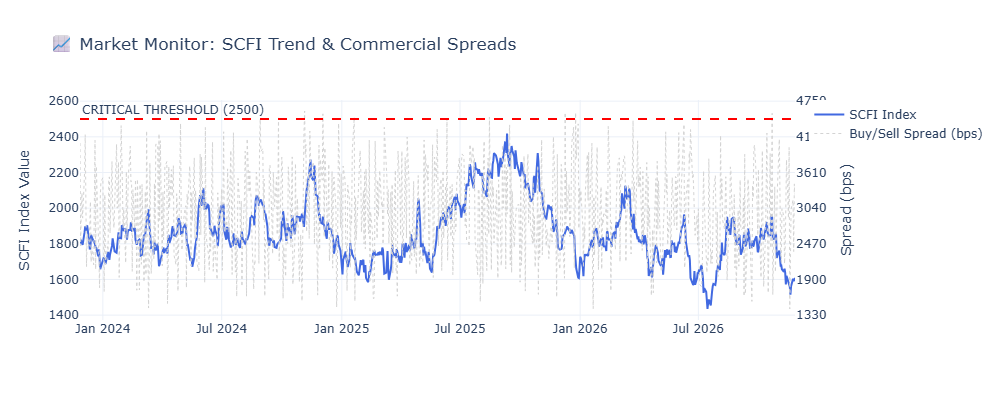

In [2]:
# --- Chart 1: SCFI Trend with Risk Thresholds ---
fig_scfi = go.Figure()

# Add SCFI Line
fig_scfi.add_trace(go.Scatter(
    x=df_freight['Date'], y=df_freight['SCFI'],
    mode='lines', name='SCFI Index',
    line=dict(color='royalblue', width=2)
))

# Add Buy/Sell Spread as a shaded area (Secondary Y-axis)
fig_scfi.add_trace(go.Scatter(
    x=df_freight['Date'], y=df_freight['Spread_bps'],
    mode='lines', name='Buy/Sell Spread (bps)',
    line=dict(color='lightgray', width=1, dash='dot'),
    yaxis='y2'
))

# Add Risk Threshold Line (e.g., SCFI > 2500 is danger zone)
fig_scfi.add_hline(y=2500, line_dash="dash", line_color="red", 
                   annotation_text="CRITICAL THRESHOLD (2500)", annotation_position="top left")

fig_scfi.update_layout(
    title="📈 Market Monitor: SCFI Trend & Commercial Spreads",
    yaxis_title="SCFI Index Value",
    yaxis2=dict(title="Spread (bps)", overlaying="y", side="right", showgrid=False),
    template="plotly_white",
    height=400
)

fig_scfi.show()

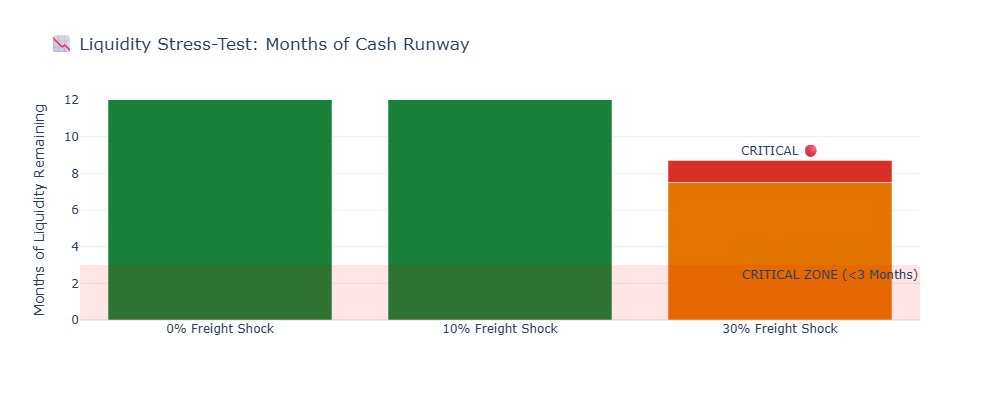

In [3]:
# --- Chart 2: Liquidity Runway Under Stress ---
# Color mapping based on our Risk Flags
colors = []
for flag in df_stress['Risk Flag']:
    if 'CRITICAL' in flag: colors.append('#d93025') # Red
    elif 'WARNING' in flag: colors.append('#f9ab00') # Orange
    elif 'CAUTION' in flag: colors.append('#e37400') # Dark Orange
    else: colors.append('#188038') # Green

fig_stress = go.Figure(data=[
    go.Bar(
        x=df_stress['Scenario'],
        y=df_stress['Liquidity Runway (Months)'],
        text=df_stress['Risk Flag'],
        textposition='outside',
        marker_color=colors,
        hovertemplate="<b>%{x}</b><br>Runway: %{y} Months<br>DSO Impact: %{customdata}<extra></extra>",
        customdata=df_stress['DSO Impact']
    )
])

fig_stress.update_layout(
    title="📉 Liquidity Stress-Test: Months of Cash Runway",
    yaxis_title="Months of Liquidity Remaining",
    template="plotly_white",
    height=400,
    yaxis=dict(range=[0, 12]) # Cap Y-axis at 12 months for visual impact
)

# Add a "Danger Zone" background for < 3 months
fig_stress.add_hrect(y0=0, y1=3, fillcolor="red", opacity=0.1, line_width=0, annotation_text="CRITICAL ZONE (<3 Months)", annotation_position="top right")

fig_stress.show()

In [4]:
# DEBUG: Let's see exactly what is in the dataframe
print(df_stress[['Scenario', 'DSO Impact', 'Effective Buffer ($M)', 'Cash Trapped in AR ($M)']])

            Scenario DSO Impact  Effective Buffer ($M)  \
0   0% Freight Shock        NaN                   30.0   
1  10% Freight Shock        NaN                   30.0   
2  30% Freight Shock        NaN                   30.0   
3  30% Freight Shock   +15 days                    5.0   

   Cash Trapped in AR ($M)  
0                      0.0  
1                      0.0  
2                      0.0  
3                     25.0  


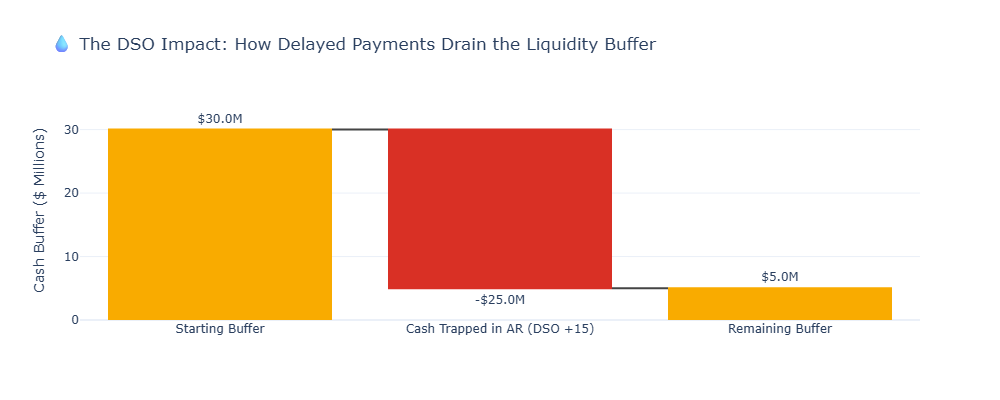

In [5]:
# --- Chart 3: Waterfall showing how DSO destroys the buffer ---

# Grab Row 2 (Index 2): 30% Shock, NO DSO impact (Baseline before crisis)
base_buffer = float(df_stress.iloc[2]['Effective Buffer ($M)'])

# Grab Row 3 (Index 3): 30% Shock, +15 Days DSO (The Compound Crisis)
cash_trapped = float(df_stress.iloc[3]['Cash Trapped in AR ($M)'])
remaining_buffer = float(df_stress.iloc[3]['Effective Buffer ($M)'])

fig_waterfall = go.Figure(go.Waterfall(
    name="Liquidity Impact",
    orientation="v",
    measure=["absolute", "relative", "total"],
    x=["Starting Buffer", "Cash Trapped in AR (DSO +15)", "Remaining Buffer"],
    y=[base_buffer, -cash_trapped, remaining_buffer],
    text=[f"${base_buffer:.1f}M", f"-${cash_trapped:.1f}M", f"${remaining_buffer:.1f}M"],
    textposition="outside",
    decreasing=dict(marker=dict(color="#d93025")),  # Red for the cash drain
    totals=dict(marker=dict(color="#f9ab00"))      # Orange for the final remaining buffer
))

fig_waterfall.update_layout(
    title="💧 The DSO Impact: How Delayed Payments Drain the Liquidity Buffer",
    yaxis_title="Cash Buffer ($ Millions)",
    template="plotly_white",
    height=400
)

fig_waterfall.show()